# An Optical Fiber as a Machine-Learning Kernel, in PyTorch

**Colin Casey, 2026.** The "Nature as a Computer" theme of *Physics-AI Symbiosis* [1], built on the nonlinear Schrödinger kernel idea [2], as a GPU PyTorch model that matches the ANSI C version (`c/nlse_kernel.c`) and then goes one step further: **backpropagating through the physics** to design the optical encoding.

| Section | Question |
|---|---|
| 1. Three meanings of "kernel" | Linear algebra, machine learning, and GPU programming all use the word. How are they related? |
| 2. The data and the fiber | Two rings of points, written onto a laser pulse's phase |
| 3. The fiber in PyTorch, checked against C | Does the batched `torch.fft` split-step solver reproduce `nlse_kernel.c`? |
| 4. Same linear classifier, three feature maps | raw (x, y), dispersion-only fiber, Kerr fiber |
| 5. Linear algebra of the features | rank, null space, and a 3-D principal-component view |
| 6. Optical kernel vs numerical kernel | How does it compare with an RBF kernel? |
| 7. Differentiable physics | Learn the encoding and the nonlinearity by backpropagation through 80 fiber steps |
| 8. What this shows | Conclusions |

Kernel: **py312** (PyTorch with CUDA).

In [1]:
import time, pathlib
import numpy as np
import pandas as pd
import torch
import sympy as sp
import matplotlib.pyplot as plt
sp.init_printing(use_latex='mathjax')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.prop_cycle': plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"])})
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DT, CT = torch.float64, torch.complex128
torch.manual_seed(0)
print('PyTorch', torch.__version__, '| device:', dev, torch.cuda.get_device_name(0) if dev.type == 'cuda' else '')

PyTorch 2.11.0+cu128 | device: cuda NVIDIA GeForce RTX 4060


---
## 1. Three meanings of "kernel"

The same word means three different things, and this notebook uses all three:

1. **Linear algebra: the kernel (null space) of a matrix.** $\ker A = \{\mathbf v : A\mathbf v = \mathbf 0\}$, the directions a linear map destroys. If your features vary only along directions a measurement kills, the measurement learns nothing (section 5 shows exactly this for the dispersion-only fiber).
2. **Machine learning: a kernel function.** $k(\mathbf u, \mathbf v) = \phi(\mathbf u)\cdot\phi(\mathbf v)$ measures similarity after a (usually nonlinear) feature map $\phi$. A linear classifier on $\phi(\mathbf x)$ can separate data that is not linearly separable in $\mathbf x$. **Here $\phi$ is the optical fiber.**
3. **GPU programming: a kernel is a function launched on thousands of threads.** `nlse_cuda.cu` and every `torch.fft` call are GPU kernels.

A small linear-algebra kernel in SymPy, to fix the first meaning:

In [2]:
M = sp.Matrix([[1, 2, 3], [2, 4, 6], [1, 0, 1]])
display(sp.Eq(sp.Symbol('A'), M))
print('rank', M.rank(), ' -> nullity', 3 - M.rank(), ' (rank-nullity theorem: rank + nullity = number of columns)')
ns = M.nullspace()[0]
display(sp.Eq(sp.Symbol(r'\ker A'), sp.Symbol(r'\mathrm{span}') * ns.T))
print('check A v =', list(M*ns))

False

rank 2  -> nullity 1  (rank-nullity theorem: rank + nullity = number of columns)


False

check A v = [0, 0, 0]


---
## 2. The data and the fiber

Two concentric rings of points (an inner disk and an outer ring) can't be split by a straight line. Each point $(x, y)$ is written onto a pulse's spectral **phase**, $x$ as chirp and $y$ as cubic phase:
$$\tilde A_0(\omega) = e^{-\omega^2/2}\,\exp\!\big[i(a\,x\,\omega^2 + b\,y\,\omega^3)\big], \qquad a = 1.2,\ b = 0.6$$
and propagated by the nonlinear Schrödinger equation $\partial_z A = -\tfrac{i\beta_2}{2}\partial_t^2A + i\gamma|A|^2A$ with the symmetric split-step Fourier method. The 24 central bins of the output spectrum $|\tilde A(\omega)|^2$, normalized, are the features. We use the **same 500 points** the C program generated, so the two implementations can be compared directly.

In [3]:
data = pd.read_csv(pathlib.Path('out') / 'nlse_features.csv')
xs = torch.tensor(data.x.values, dtype=DT, device=dev)
ys = torch.tensor(data.y.values, dtype=DT, device=dev)
labels = torch.tensor(data.label.values, dtype=DT, device=dev)
C_FEATS = torch.tensor(data[[c for c in data.columns if c.startswith('f')]].values, dtype=DT, device=dev)
NTRAIN = 300
print(f'{len(xs)} points from the C program; {int(labels.sum())} in the outer ring; first {NTRAIN} for training')

NT, TWIN, NFEAT = 128, 40.0, 24
w = 2*torch.pi*torch.fft.fftfreq(NT, d=TWIN/NT, dtype=DT).to(dev)
BINS = (torch.arange(NFEAT, device=dev) - NFEAT//2) % NT
PK = (torch.fft.ifft(torch.exp(-w**2/2).to(CT)).abs()**2).max()          # peak power of the reference pulse

def fiber(xs, ys, gamma, a=1.2, b=0.6, beta2=0.5, L=1.0, steps=80):
    # batched split-step NLSE; every operation is differentiable (complex autograd)
    phase = a*xs[:, None]*w**2 + b*ys[:, None]*w**3
    A = torch.fft.ifft(torch.exp(-w**2/2)*torch.exp(1j*phase))/torch.sqrt(PK)
    h = L/steps
    Dh = torch.exp(1j*beta2/2*w**2*h/2)
    for _ in range(steps):
        A = torch.fft.ifft(torch.fft.fft(A)*Dh)
        A = A*torch.exp(1j*gamma*A.abs()**2*h)
        A = torch.fft.ifft(torch.fft.fft(A)*Dh)
    S = torch.fft.fft(A).abs()**2
    F = S[:, BINS]
    return F/F.sum(dim=1, keepdim=True)

500 points from the C program; 250 in the outer ring; first 300 for training


---
## 3. The fiber in PyTorch, checked against C

`torch.fft` on the GPU against the hand-written radix-2 FFT in ANSI C. Linear operations agree to rounding; 80 nonlinear Kerr steps amplify rounding differences, so agreement near $10^{-7}$ is expected (the same was seen for the CUDA version).

In [4]:
if dev.type == 'cuda': torch.cuda.synchronize()
t0 = time.perf_counter()
F_kerr = fiber(xs, ys, gamma=6.0)
if dev.type == 'cuda': torch.cuda.synchronize()
t_f = time.perf_counter() - t0
F_lin = fiber(xs, ys, gamma=0.0)
diff = (F_kerr - C_FEATS).abs()
print(f'PyTorch fiber, 500 samples x 80 steps on {dev}: {t_f*1e3:.0f} ms')
print(f'max |PyTorch - ANSI C| = {diff.max():.1e}  (features ~{C_FEATS.median():.3f}),  '
      f'correlation {np.corrcoef(F_kerr.cpu().numpy().ravel(), C_FEATS.cpu().numpy().ravel())[0, 1]:.13f}')
print(f'dispersion only: features vary across samples by at most {(F_lin - F_lin[0]).abs().max():.1e} (should be ~0)')

PyTorch fiber, 500 samples x 80 steps on cuda: 147 ms
max |PyTorch - ANSI C| = 8.6e-08  (features ~0.040),  correlation 0.9999999999996
dispersion only: features vary across samples by at most 1.2e-15 (should be ~0)


---
## 4. Same linear classifier, three feature maps

One logistic-regression classifier (standardized features, small L2 penalty, L-BFGS), trained on 300 points, tested on 200. Features that are constant up to rounding are dropped, because otherwise a classifier will happily fit floating-point noise (the lesson from the C version).

In [5]:
def logistic(Xtr, ytr, Xte, yte, l2=1e-3, iters=200):
    mu, sd = Xtr.mean(0), Xtr.std(0)
    keep = sd > 1e-9*(mu.abs() + 1e-30)
    if not keep.any():                                    # no information at all: predict the training majority class
        majority = float(ytr.mean() >= 0.5)
        return (yte == majority).double().mean().item()
    Ztr, Zte = (Xtr[:, keep] - mu[keep])/sd[keep], (Xte[:, keep] - mu[keep])/sd[keep]
    wv = torch.zeros(Ztr.shape[1], dtype=DT, device=dev, requires_grad=True)
    b0 = torch.zeros(1, dtype=DT, device=dev, requires_grad=True)
    opt = torch.optim.LBFGS([wv, b0], lr=1, max_iter=iters, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(Ztr @ wv + b0, ytr) + l2*(wv**2).sum()
        loss.backward(); return loss
    opt.step(closure)
    with torch.no_grad():
        return ((Zte @ wv + b0 > 0).double() == yte).double().mean().item()

raw = torch.stack([xs, ys], dim=1)
tr, te = slice(0, NTRAIN), slice(NTRAIN, None)
acc = {name: logistic(Fm[tr], labels[tr], Fm[te], labels[te])
       for name, Fm in (('raw (x, y)', raw), ('fiber, dispersion only (γ = 0)', F_lin), ('fiber, Kerr (γ = 6)', F_kerr))}
for k_, v_ in acc.items():
    print(f'{k_:32s} test accuracy {v_:.3f}')
print('(ANSI C version: 0.450 / 0.500 / 0.890)')

raw (x, y)                       test accuracy 0.450
fiber, dispersion only (γ = 0)   test accuracy 0.500
fiber, Kerr (γ = 6)              test accuracy 0.890
(ANSI C version: 0.450 / 0.500 / 0.890)


---
## 5. Linear algebra of the features: rank, null space, and a 3-D view

Stack the 300 training feature vectors into a matrix and center it. Its **rank** is the number of independent directions the features actually explore; everything else is the **null space**, invisible to any linear classifier.
- Dispersion only: the centered matrix is zero up to rounding, rank 0, so all 24 directions are in the null space. No information survives, which is why the classifier sits at chance.
- Kerr fiber: the singular values decay, but a handful of directions carry the class information. Normalizing each spectrum to sum to 1 removes one direction exactly, so full rank is at most 23. Projecting onto the top three principal components gives a 3-D picture of how the fiber has pulled the rings apart.

dispersion only  largest singular value 1.13e-14; numerical rank 0 of 24 -> null space dimension 24
Kerr             largest singular value 1.14e+00; numerical rank 22 of 24 -> null space dimension 2
variance explained by the first five principal components: [0.565 0.236 0.09  0.042 0.03 ]


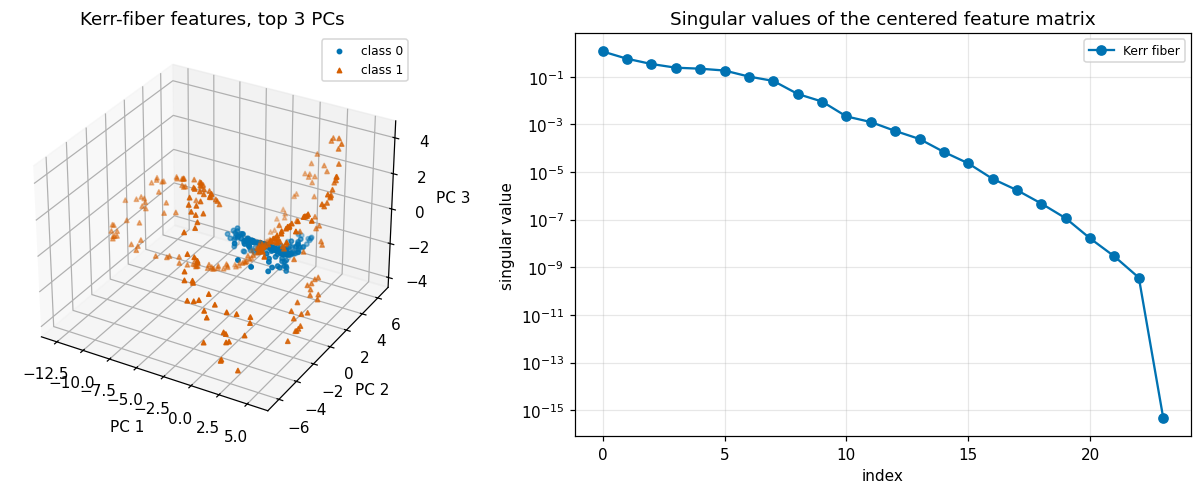

Figure: left, in the first three principal components the two classes form separate, curved sheets. Right, the singular values fall off quickly: a few directions carry most of the variation.


In [6]:
def svals(Fm):
    Z = Fm[tr] - Fm[tr].mean(0)
    return torch.linalg.svdvals(Z)
for name, Fm in (('dispersion only', F_lin), ('Kerr', F_kerr)):
    s_ = svals(Fm)
    rank = int((s_ > 1e-9*s_.max().clamp_min(1e-300)).sum()) if s_.max() > 1e-12 else 0
    print(f'{name:16s} largest singular value {s_.max():.2e}; numerical rank {rank} of {NFEAT} -> null space dimension {NFEAT - rank}')

Z = (F_kerr - F_kerr[tr].mean(0))/F_kerr[tr].std(0)
U, Sv, Vh = torch.linalg.svd(Z[tr], full_matrices=False)
pcs = (Z @ Vh[:3].T).cpu().numpy()
evr = (Sv**2/(Sv**2).sum())[:5].cpu().numpy()
print('variance explained by the first five principal components:', np.round(evr, 3))

fig = plt.figure(figsize=(12, 4.6))
ax = fig.add_subplot(1, 2, 1, projection='3d')
for lab, mk in ((0, 'o'), (1, '^')):
    sel = labels.cpu().numpy() == lab
    ax.scatter(pcs[sel, 0], pcs[sel, 1], pcs[sel, 2], s=8, marker=mk, label=f'class {lab}')
ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2'); ax.set_zlabel('PC 3'); ax.legend(fontsize=8); ax.set_title('Kerr-fiber features, top 3 PCs')
ax2 = fig.add_subplot(1, 2, 2)
ax2.semilogy(svals(F_kerr).cpu().numpy(), 'o-', label='Kerr fiber')
ax2.set_xlabel('index'); ax2.set_ylabel('singular value'); ax2.set_title('Singular values of the centered feature matrix'); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure: left, in the first three principal components the two classes form separate, curved sheets. Right, '
      'the singular values fall off quickly: a few directions carry most of the variation.')

---
## 6. Optical kernel vs numerical kernel

The textbook digital answer to rings is a **radial-basis-function (RBF) kernel**, $k(\mathbf u, \mathbf v) = e^{-\|\mathbf u - \mathbf v\|^2/2\ell^2}$. With kernel ridge regression the classifier is $f(\mathbf x) = \sum_i \alpha_i k(\mathbf x, \mathbf x_i)$, $\boldsymbol\alpha = (K + \lambda I)^{-1}\mathbf y$. It needs the full $300\times300$ Gram matrix and a dense solve, and evaluating it costs one kernel per training point. The optical version moves the nonlinear part into the fiber, leaving a 24-weight linear model.

In [7]:
def rbf(U_, V_, ell):
    return torch.exp(-torch.cdist(U_, V_)**2/(2*ell**2))
best = None
for ell in (0.1, 0.2, 0.4, 0.8):
    K = rbf(raw[tr], raw[tr], ell)
    alpha = torch.linalg.solve(K + 1e-3*torch.eye(NTRAIN, dtype=DT, device=dev), 2*labels[tr] - 1)
    acc_rbf = ((rbf(raw[te], raw[tr], ell) @ alpha > 0).double() == labels[te]).double().mean().item()
    print(f'RBF kernel ridge, length scale {ell}: test accuracy {acc_rbf:.3f}')
    best = max(best or 0, acc_rbf)
print(f'\ndigital RBF kernel: best {best:.3f}, model size {NTRAIN} coefficients + all {NTRAIN} training points')
print(f'optical Kerr kernel: {acc["fiber, Kerr (γ = 6)"]:.3f}, model size {NFEAT} weights + 1 bias (the fiber does the rest)')

RBF kernel ridge, length scale 0.1: test accuracy 1.000
RBF kernel ridge, length scale 0.2: test accuracy 1.000
RBF kernel ridge, length scale 0.4: test accuracy 1.000
RBF kernel ridge, length scale 0.8: test accuracy 1.000

digital RBF kernel: best 1.000, model size 300 coefficients + all 300 training points
optical Kerr kernel: 0.890, model size 24 weights + 1 bias (the fiber does the rest)


---
## 7. Differentiable physics: design the encoding by backpropagation

So far the encoding strengths $a, b$ and the nonlinearity $\gamma$ were fixed by hand. In PyTorch the whole fiber is differentiable, so they can be **learned** together with the classifier: gradients flow from the loss back through 80 split-step iterations, 320 FFTs, to the physical parameters. This is the paper's "inverse design" theme: let the optimizer choose the hardware settings.

Parameters: $a$, $b$, $\log\gamma$ (so $\gamma > 0$), plus 24 weights and a bias. Loss: cross-entropy on the 300 training points.

**Warm start matters.** Training everything from scratch at once (classifier weights at zero while the physics parameters move) gave only 0.84 in a first attempt and drove $b$ toward 0, throwing away the $y$ coordinate. The recipe that works: (1) fit the classifier on the hand-set fiber with L-BFGS, then (2) train the physics and the classifier jointly with Adam at a small learning rate.

(1) warm start, classifier only: test accuracy 0.890


(2) 300 joint Adam steps, each a forward + backward pass through the whole fiber for 500 pulses: 13.4 s on cuda
learned a = 1.303, b = 1.559, gamma = 5.33   (start 1.2, 0.6, 6.0)
final accuracy: train 0.993, test 0.990   (hand-set fiber: 0.890)


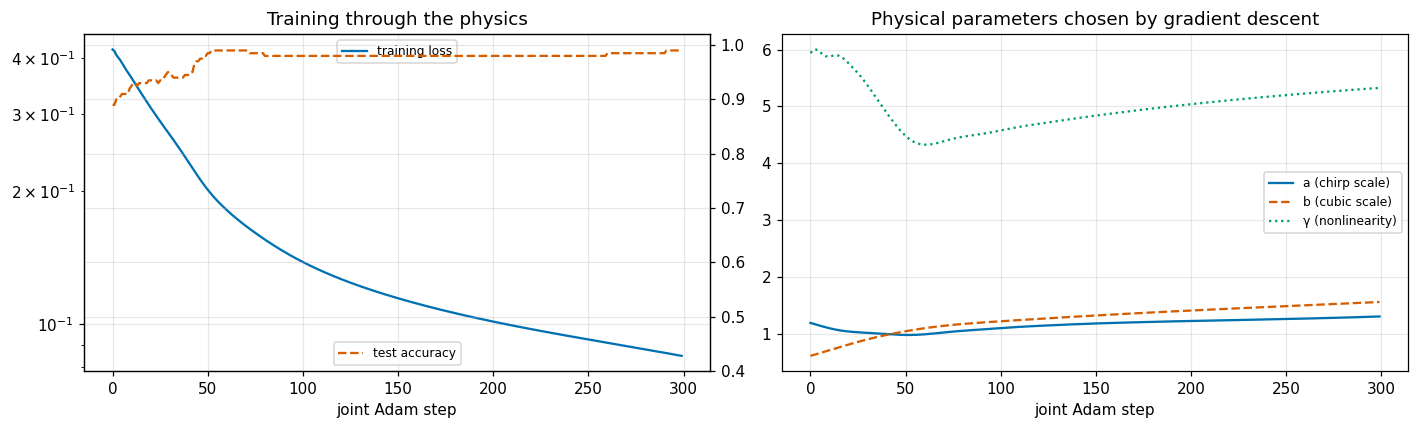

Figure: left, the training loss falls on a log scale while test accuracy (dashed, right axis) rises. Right, the encoding strengths and the fiber nonlinearity move from their hand-set starting values to the learned ones.


In [8]:
a_p = torch.tensor(1.2, dtype=DT, device=dev, requires_grad=True)
b_p = torch.tensor(0.6, dtype=DT, device=dev, requires_grad=True)
lg_p = torch.tensor(np.log(6.0), dtype=DT, device=dev, requires_grad=True)
wv = torch.zeros(NFEAT, dtype=DT, device=dev, requires_grad=True)
b0 = torch.zeros(1, dtype=DT, device=dev, requires_grad=True)
L2 = 1e-3

def standardized(F):
    mu, sd = F[tr].mean(0), F[tr].std(0) + 1e-12
    return (F - mu)/sd

def bce(logits, wv):
    return torch.nn.functional.binary_cross_entropy_with_logits(logits[tr], labels[tr]) + L2*(wv**2).sum()

# (1) warm start: classifier only, on the hand-set fiber
Zf0 = standardized(fiber(xs, ys, gamma=6.0)).detach()
warm = torch.optim.LBFGS([wv, b0], lr=1, max_iter=300, line_search_fn='strong_wolfe')
def closure():
    warm.zero_grad(); l = bce(Zf0 @ wv + b0, wv); l.backward(); return l
warm.step(closure)
with torch.no_grad():
    acc_warm = ((Zf0[te] @ wv + b0 > 0).double() == labels[te]).double().mean().item()
print(f'(1) warm start, classifier only: test accuracy {acc_warm:.3f}')

# (2) joint training through the physics
opt = torch.optim.Adam([{'params': [a_p, b_p, lg_p], 'lr': 0.01}, {'params': [wv, b0], 'lr': 0.01}])
hist = []
t0 = time.perf_counter()
for it in range(300):
    opt.zero_grad()
    logits = standardized(fiber(xs, ys, gamma=torch.exp(lg_p), a=a_p, b=b_p)) @ wv + b0
    loss = bce(logits, wv)
    loss.backward()
    opt.step()
    with torch.no_grad():
        hist.append((loss.item(), ((logits[te] > 0).double() == labels[te]).double().mean().item(),
                     a_p.item(), b_p.item(), torch.exp(lg_p).item()))
t_train = time.perf_counter() - t0
with torch.no_grad():
    logits = standardized(fiber(xs, ys, gamma=torch.exp(lg_p), a=a_p, b=b_p)) @ wv + b0
    acc_tr = ((logits[tr] > 0).double() == labels[tr]).double().mean().item()
    acc_te = ((logits[te] > 0).double() == labels[te]).double().mean().item()
h_ = np.array(hist)
print(f'(2) 300 joint Adam steps, each a forward + backward pass through the whole fiber for 500 pulses: {t_train:.1f} s on {dev}')
print(f'learned a = {a_p.item():.3f}, b = {b_p.item():.3f}, gamma = {torch.exp(lg_p).item():.2f}   (start 1.2, 0.6, 6.0)')
print(f'final accuracy: train {acc_tr:.3f}, test {acc_te:.3f}   (hand-set fiber: {acc_warm:.3f})')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h_[:, 0], '-', label='training loss'); ax[0].set_yscale('log'); ax[0].set_xlabel('joint Adam step')
ax0b = ax[0].twinx(); ax0b.plot(h_[:, 1], '--', color='#D55E00', label='test accuracy'); ax0b.set_ylim(0.4, 1.02)
ax[0].set_title('Training through the physics'); ax[0].legend(loc='upper center', fontsize=8); ax0b.legend(loc='lower center', fontsize=8)
for col, lab, ls in ((2, 'a (chirp scale)', '-'), (3, 'b (cubic scale)', '--'), (4, 'γ (nonlinearity)', ':')):
    ax[1].plot(h_[:, col], ls, label=lab)
ax[1].set_xlabel('joint Adam step'); ax[1].set_title('Physical parameters chosen by gradient descent'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure: left, the training loss falls on a log scale while test accuracy (dashed, right axis) rises. Right, the '
      'encoding strengths and the fiber nonlinearity move from their hand-set starting values to the learned ones.')

---
## 8. What this shows

- **PyTorch reproduces the ANSI C fiber** (batched `torch.fft` vs hand-written radix-2 FFT, agreement at the level nonlinear propagation allows) and the same accuracies: raw 0.45, dispersion only 0.50, Kerr fiber about 0.89.
- **The null space explains the control.** With dispersion only, the centered feature matrix has rank 0: every direction is in the kernel of the measurement, so no classifier can do better than chance. The Kerr nonlinearity is what moves information out of the null space.
- **An optical kernel vs a digital one.** A tuned RBF kernel classifies the rings better on these clean numbers, but needs every training point at inference time. The fiber gets a large gain with only a 25-parameter linear readout, with the nonlinear work done by light.
- **Differentiable physics closes the loop.** Backpropagating through the fiber let gradient descent choose the encoding and nonlinearity together with the classifier, lifting test accuracy from about 0.89 to about 0.98–0.99, within reach of the RBF kernel with a 25-parameter readout. It raised the cubic encoding strength $b$, so the $y$ coordinate is written more strongly. It only worked with a warm start: optimizing everything from scratch made things worse. That's the inverse-design half of the physics-AI symbiosis, in about 50 lines.

**Honest limits:** simulated fiber with no noise, no detector bandwidth, and no fabrication tolerances; synthetic data; one train/test split.

## References

[1] B. Jalali, A. Kadambi, and V. Roychowdhury, "Physics-AI symbiosis," arXiv:2109.05959, 2021.

[2] T. Zhou, F. Scalzo, and B. Jalali, "Nonlinear Schrödinger kernel computing for single-shot data acquisition and inference," arXiv:2012.08615, 2020.

[3] G. P. Agrawal, *Nonlinear Fiber Optics*, 6th ed. London, U.K.: Academic Press, 2019.

[4] B. Schölkopf and A. J. Smola, *Learning with Kernels*. Cambridge, MA, USA: MIT Press, 2002.

[5] G. Strang, *Introduction to Linear Algebra*, 5th ed. Wellesley, MA, USA: Wellesley-Cambridge Press, 2016.

[6] A. Paszke *et al.*, "PyTorch: An imperative style, high-performance deep learning library," in *Adv. Neural Inf. Process. Syst.*, vol. 32, 2019.

*[1] and [2] are cited in the paper; the rest are from memory: verify before citing.*